# Phần 3 (batch size = 2) — R-GAP: khi nào KHÔNG tách được ảnh

**Pillar:** Security — privacy trong Federated Learning (FL).

Notebook này lặp lại attack ở `part3.ipynb` nhưng với **client tính gradient trên batch 2 ảnh**
thay vì 1 — song song với `part1_batch2.ipynb` (DLG/iDLG batch 2). Paper R-GAP tự chỉ ra một
giới hạn căn bản:

> *"It can be verified straightforwardly that R-GAP in the batch setting will return a linear
> combination of the training data. This is due to the fact that in the batch setting the
> gradients are simply accumulated..."* — Zhu \& Blaschko, ICLR 2021, Section 6 (Discussion).

**Vì sao so sánh 2 kiến trúc.** Khi áp dụng R-GAP batch=2 cho kiến trúc có conv (LeNet/CNN trên
CIFAR-10), ảnh cuối thu được **tệ hơn** cả "linear combination" — gần như nhiễu thuần túy. Lý do
hoá ra không nằm ở nguyên lý "trộn ảnh" của R-GAP, mà ở **các layer conv**: mỗi conv layer cộng
thêm một ràng buộc forward-pass ($Wx=\mathrm{out}$) không hợp lệ cho một tín hiệu đã bị trộn. Repo
gốc **chưa từng test batch>1 trên kiến trúc có conv** — ví dụ batch>1 duy nhất họ test
(`python main.py -m FCN3 -d MNIST -b 5`) dùng **FCN3, một mạng chỉ có Linear layer**, không
có conv nào. Notebook này chạy **cả hai kiến trúc trên đúng cùng một cặp ảnh** (lấy từ CIFAR-10,
giống Kiến trúc A) để cô lập chính xác nguyên nhân: khác biệt duy nhất giữa hai thí nghiệm là
kiến trúc model (có conv hay không), không phải nội dung ảnh hay dataset.

**Nguồn.** `rgap/models.py::FCN3` là bản port **không chỉnh sửa** từ `models/FCN3.py` của repo
gốc (3 Linear layer bias-free, LeakyReLU trên mọi layer kể cả layer cuối — khác với `LeNetRGAP`
dùng Identity ở layer cuối). Thuật toán tấn công (`run_rgap`) giữ nguyên, không đổi gì giữa 2
kiến trúc — chỉ khác input/model, đúng tinh thần "dễ so sánh".

In [1]:
import sys, os, time
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))   # repo root, so `import rgap` (shared package) resolves

import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

from rgap import LeNetRGAP, FCN3
from rgap.recursive_attack import r_gap, peeling, fcn_reconstruction, inverse_udldu
from rgap.utils import logistic_loss, inverse_leakyrelu, derive_leakyrelu, inverse_identity, derive_identity

torch.manual_seed(50)
np.random.seed(50)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on %s" % device)
print(torch.__version__, torchvision.__version__)

Running on cuda
2.10.0+cu128 0.25.0+cu128


## 0. Hạ tầng dùng chung cho cả 2 kiến trúc

`run_rgap` **y hệt** `part3.ipynb`, chỉ thêm việc ép batch dimension của `x_shape` về 1 (xem
docstring trong hàm) — phản ánh đúng thực tế toán học: `k`/`g` ở mọi layer đều là tín hiệu đã
**trung bình cộng qua batch**, nên hệ phương trình luôn giải ra một vector duy nhất mỗi layer,
bất kể batch size thật. `forward_with_intermediates` và `plot_stage_cos_sim` dùng chung cho cả
LeNet và FCN3 — phần duy nhất khác nhau giữa 2 thí nghiệm là shape/tên của từng "stage", khai
báo riêng ở mỗi kiến trúc.

In [ ]:
def run_rgap(model, gradients, y, x_shape, device, dtype=torch.float64, collect=False):
    # Recursive R-GAP attack: peel `model` layer by layer from output to input.
    # Mirrors the reference repo's main.py attack loop (see rgap/recursive_attack.py).
    # Batch dimension of every x_shape entry is forced to 1: k/g are batch-averaged signals,
    # so R-GAP always solves for ONE combined vector per layer regardless of true batch size.
    modules = model.body[-1::-1]
    gradients = list(reversed(gradients))
    x_shape_rev = [tuple([1] + list(s[1:])) for s in reversed(x_shape)]
    k, last_weight, x_, out = None, None, None, None
    history = []

    for i in range(len(modules)):
        g = gradients[i].detach().cpu().numpy().astype(np.float64)
        w = list(modules[i].layer.parameters())[0].detach().cpu().numpy().astype(np.float64)

        if k is None:
            # output layer: solve the scalar equation for u, then k = dL/du
            udldu = np.dot(g.reshape(-1), w.reshape(-1))
            u = inverse_udldu(udldu, device=device, dtype=dtype)
            y_bipolar = np.array([-1.0 if n == 0 else n for n in y.cpu().numpy()], dtype=np.float64).reshape(-1, 1)
            y_scalar = y_bipolar.mean() if y_bipolar.mean() != 0 else 0.1
            k = (-y_scalar / (1 + np.exp(u))).reshape(1, -1).astype(np.float64)
        else:
            act = modules[i].act
            if isinstance(act, nn.LeakyReLU):
                da, out = derive_leakyrelu(x_, slope=act.negative_slope), inverse_leakyrelu(x_, slope=act.negative_slope)
            elif isinstance(act, nn.Identity):
                da, out = derive_identity(x_), inverse_identity(x_)
            else:
                raise ValueError(f'no inverse/derivative implemented for {act}')

            padding = modules[i - 1].layer.padding[0] if hasattr(modules[i - 1].layer, 'padding') else 0
            in_shape = np.array(x_shape_rev[i - 1]); in_shape[0] = 1
            x_mask = peeling(in_shape=in_shape, padding=padding)
            k = np.multiply(np.matmul(last_weight.transpose(), k)[x_mask], da.transpose())

        if isinstance(modules[i].layer, nn.Conv2d):
            x_, last_weight = r_gap(out=out, k=k, x_shape=x_shape_rev[i], module=modules[i], g=g, weight=w)
        else:
            x_, last_weight = fcn_reconstruction(k=k, gradient=g), w
        if collect:
            history.append(x_.copy())

    return (x_, history) if collect else x_


def forward_with_intermediates(model, x):
    # true post-activation output after every block, in feedforward order
    outs = []
    for block in model.body:
        if isinstance(block.layer, nn.Linear):
            x = x.flatten(1)
        x = block(x)
        outs.append(x)
    return outs


def cos_sim_np(a, b):
    a, b = a.flatten(), b.flatten()
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))


def rescale_for_display(x):
    # Used only for the FCN3 panel (section 2): R-GAP's linear system does not fix an
    # overall sign/scale for the recovered x (e.g. a perfect reconstruction can land on
    # -1 * target, which is exactly what happens for some image pairs here) - the reference
    # repo's own main.py handles this the same way, saving a min-max "rescale_reconstructed"
    # version alongside the raw one. Plain clamp(0,1) on a negative-dominated solution would
    # just render as solid black, hiding an otherwise-correct result.
    #
    # Deliberately NOT used for the LeNet/CNN panel (section 1): that reconstruction is
    # genuinely garbage (most pixels land far outside [0,1], some past +-800 - see section 1's
    # markdown). A rescale there - min-max or percentile-based - would manufacture visual
    # structure that isn't really present in the data. Section 1 shows that panel with a plain
    # .clamp(0, 1) instead, same as every other reconstruction panel in this project
    # (part1/part2/part3), so a failed attack still looks like one. Either way, every reported
    # cosine similarity is computed on the raw, unrescaled/unclipped reconstruction, never on
    # this display-only transform.
    x = x - x.min()
    return x / (x.max() + 1e-12)


def run_batch2_attack(model, gt_data, device, dtype=torch.float64):
    # shared pipeline: cast to float64, attack-label each image, compute the leaked
    # gradient, run R-GAP with collect=True. Identical for every architecture.
    model64 = model.double().to(device)
    model64.eval()
    gt_data64 = gt_data.double().to(device)
    pred, x_shape = model64(gt_data64)
    attack_label = torch.tensor([0.0 if p.item() > 0 else 1.0 for p in pred.flatten()], dtype=dtype, device=device)
    loss = logistic_loss(target=attack_label, inputs=pred.squeeze(-1))
    dy_dx = torch.autograd.grad(loss, list(model64.parameters()))
    original_dy_dx = [g.detach().clone() for g in dy_dx]
    x_rec_flat, history = run_rgap(model64, original_dy_dx, attack_label, x_shape, device, collect=True)
    true_ff = forward_with_intermediates(model64, gt_data64)
    return dict(model64=model64, gt_data64=gt_data64, pred=pred, attack_label=attack_label,
               history=history, true_ff=true_ff, x_rec_flat=x_rec_flat)


def plot_stage_cos_sim(true_A, true_B, history, stage_shapes, stage_names, title):
    cos_A, cos_B, cos_avg = [], [], []
    for i in range(len(stage_shapes)):
        a = true_A[i].detach().cpu().numpy().reshape(stage_shapes[i])
        b = true_B[i].detach().cpu().numpy().reshape(stage_shapes[i])
        rec = np.asarray(history[i]).reshape(stage_shapes[i])
        cos_A.append(cos_sim_np(rec, a)); cos_B.append(cos_sim_np(rec, b)); cos_avg.append(cos_sim_np(rec, (a + b) / 2))

    plt.figure(figsize=(6.8, 3.4))
    xs = range(len(stage_shapes))
    plt.plot(xs, cos_A, marker='o', label='cos sim vs image A')
    plt.plot(xs, cos_B, marker='o', label='cos sim vs image B')
    plt.plot(xs, cos_avg, marker='o', linestyle='--', label='cos sim vs plain average (A+B)/2')
    plt.xticks(list(xs), stage_names, fontsize=8)
    plt.ylabel("cosine similarity"); plt.axhline(0, color='gray', lw=0.7)
    plt.title(title); plt.legend(fontsize=8); plt.tight_layout(); plt.show()
    return cos_A, cos_B, cos_avg

## 1. Kiến trúc A — LeNet (CNN) trên CIFAR-10

Dùng đúng `LeNetRGAP` như `part3.ipynb` (4 conv layer bias-free + LeakyReLU, head 1 logit).
Chọn ảnh theo đúng quy tắc của `part1_batch2.ipynb`: `img_index = 6`, ảnh thứ hai là ảnh tiếp
theo khác class.

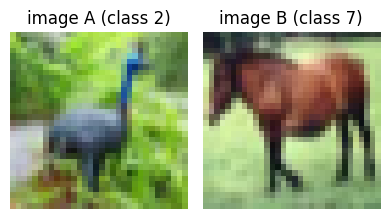

In [3]:
dst_cifar = datasets.CIFAR10("../part1_dlg_lenet/data", download=True)
tp_cifar = transforms.Compose([transforms.Resize(32), transforms.CenterCrop(32), transforms.ToTensor()])
tt_cifar = transforms.ToPILImage()

cifar_indices = [6]
j = cifar_indices[0] + 1
while dst_cifar[j][1] == dst_cifar[cifar_indices[0]][1]:
    j += 1
cifar_indices.append(j)

gt_cifar = torch.stack([tp_cifar(dst_cifar[i][0]) for i in cifar_indices])   # [2, 3, 32, 32]
cifar_labels = [dst_cifar[i][1] for i in cifar_indices]

fig, axes = plt.subplots(1, 2, figsize=(4, 2.4))
for b in range(2):
    axes[b].imshow(tt_cifar(gt_cifar[b])); axes[b].set_title("image %s (class %d)" % ("AB"[b], cifar_labels[b])); axes[b].axis('off')
plt.tight_layout(); plt.show()

[R-GAP] inverse_udldu residual: 1.07e-05


[R-GAP] lstsq residual: [0.00043148], rank: 1728 -> 1728, max/min singular value: 1.25e+00/7.32e-02


[R-GAP] lstsq residual: [0.00779871], rank: 1728 -> 1728, max/min singular value: 1.24e+00/3.17e-02


[R-GAP] lstsq residual: [0.00273626], rank: 4800 -> 4800, max/min singular value: 1.17e+00/2.63e-04


[R-GAP] lstsq residual: [58.28925694], rank: 3888 -> 3888, max/min singular value: 1.29e+00/3.93e-04
CNN (LeNetRGAP) R-GAP time: 59.5s
attack labels: [0.0, 0.0] | true CIFAR labels (unused): [2, 7]


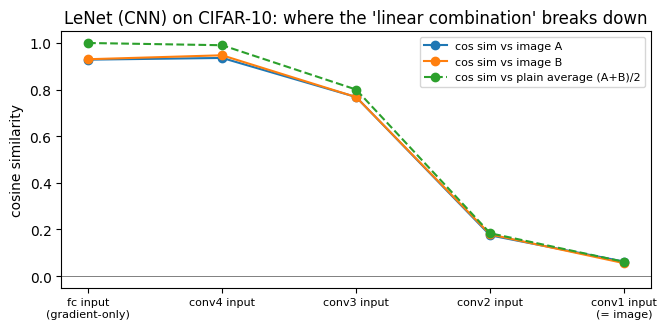

In [4]:
net_cnn = LeNetRGAP()
t0 = time.time()
res_cnn = run_batch2_attack(net_cnn, gt_cifar, device)
print("CNN (LeNetRGAP) R-GAP time: %.1fs" % (time.time() - t0))
print("attack labels:", res_cnn['attack_label'].tolist(), "| true CIFAR labels (unused):", cifar_labels)

cnn_stage_shapes = [(12, 8, 8), (12, 8, 8), (12, 8, 8), (12, 16, 16), (3, 32, 32)]
cnn_stage_names = ["fc input\n(gradient-only)", "conv4 input", "conv3 input", "conv2 input", "conv1 input\n(= image)"]
true_ff = res_cnn['true_ff']
cnn_true_A = [true_ff[3][0], true_ff[2][0], true_ff[1][0], true_ff[0][0], res_cnn['gt_data64'][0]]
cnn_true_B = [true_ff[3][1], true_ff[2][1], true_ff[1][1], true_ff[0][1], res_cnn['gt_data64'][1]]

cnn_cos_A, cnn_cos_B, cnn_cos_avg = plot_stage_cos_sim(
    cnn_true_A, cnn_true_B, res_cnn['history'], cnn_stage_shapes, cnn_stage_names,
    "LeNet (CNN) on CIFAR-10: where the 'linear combination' breaks down")

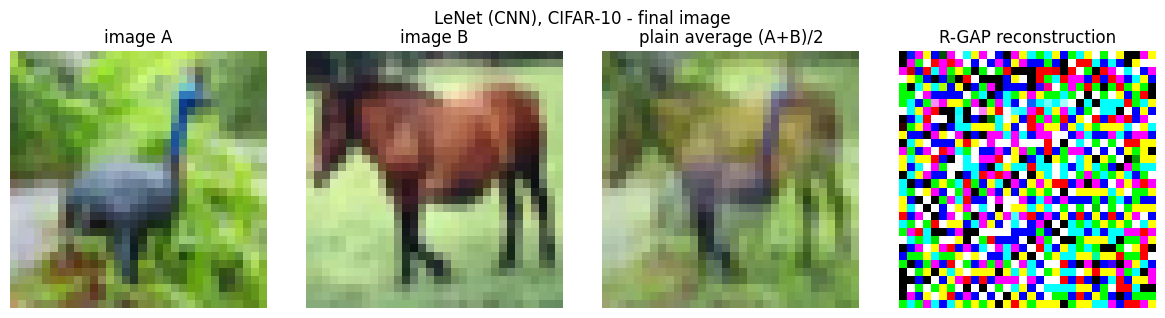

final-stage cos sim -> vs A: 0.0617 | vs B: 0.0550 | vs avg: 0.0608


In [5]:
x_rec_cnn = torch.tensor(res_cnn['x_rec_flat'].reshape(gt_cifar.shape[-3:]), dtype=torch.float32)
avg_cifar = gt_cifar.mean(dim=0)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
axes[0].imshow(tt_cifar(gt_cifar[0])); axes[0].set_title("image A"); axes[0].axis('off')
axes[1].imshow(tt_cifar(gt_cifar[1])); axes[1].set_title("image B"); axes[1].axis('off')
axes[2].imshow(tt_cifar(avg_cifar.clamp(0, 1))); axes[2].set_title("plain average (A+B)/2"); axes[2].axis('off')
axes[3].imshow(tt_cifar(x_rec_cnn.clamp(0, 1))); axes[3].axis('off'); axes[3].set_title("R-GAP reconstruction")
plt.suptitle("LeNet (CNN), CIFAR-10 - final image")
plt.tight_layout(); plt.show()

print("final-stage cos sim -> vs A: %.4f | vs B: %.4f | vs avg: %.4f" % (cnn_cos_A[-1], cnn_cos_B[-1], cnn_cos_avg[-1]))

## 2. Kiến trúc B — FCN3, trên đúng 2 ảnh của Kiến trúc A

`rgap/models.py::FCN3` — port không chỉnh sửa (3 Linear layer bias-free, LeakyReLU cả ở layer
cuối). Không có conv layer nào, nên **không có ràng buộc forward-pass nào ngoài ràng buộc
gradient** ở bất kỳ layer nào — đây chính xác là điều kiện cần cho "linear combination" hoạt
động sạch theo lý thuyết ở mục 1.

**Cùng ảnh, cùng số kênh màu.** Để so sánh công bằng nhất (chỉ đổi kiến trúc, giữ nguyên nội dung
*và định dạng* ảnh), mục này dùng lại **đúng 2 ảnh CIFAR-10 RGB** (`cifar_indices`) đã dùng ở
mục 1 — không tải MNIST, không chuyển grayscale. Bản gốc của FCN3 cố định input $784=28{\times}28{\times}1$
(thiết kế cho MNIST xám); `rgap/models.py::FCN3` thêm tham số `input_dim` (mặc định vẫn `784`)
để nhận ảnh $28\times28\times3$ ($=2352$) thay vì ép ảnh về 1 kênh — mọi kích thước khác (1000,
100, 1 unit) và mọi tính chất khác (bias-free, LeakyReLU mọi layer) giữ nguyên bản gốc. 2 ảnh
$32\times32\times3$ chỉ được **resize còn $28\times28$** (giữ 3 kênh), không grayscale.

**Lưu ý về nhãn tấn công.** Quy ước nhãn (chọn class model *không* dự đoán) đôi khi khiến 2 ảnh
trong batch nhận **nhãn bipolar trái dấu** ($y_A=-1, y_B=+1$); khi đó `y_scalar` (trung bình
cộng) bằng 0, và code gốc dùng giá trị fallback `0.1` — một xấp xỉ thô, không suy ra từ dữ liệu.
Với đúng cặp ảnh và seed đang dùng, 2 ảnh này cho prediction **cùng dấu** (đã kiểm tra), nên
không rơi vào trường hợp suy biến đó.

**Lưu ý về dấu/scale.** Hệ phương trình R-GAP giải không cố định dấu hay độ lớn tổng thể của
nghiệm $x$ — một nghiệm $-x$ khớp ràng buộc tuyến tính y hệt $x$. Vì vậy ảnh "R-GAP
reconstruction" ở mục dưới được hiển thị sau khi **rescale min-max** (`rescale_for_display`)
thay vì clamp trực tiếp về $[0,1]$ — đúng cách repo gốc cũng làm (`main.py` lưu thêm một bản
`rescale_reconstructed` bên cạnh bản gốc). Cosine similarity báo cáo vẫn tính trên giá trị thô,
chưa rescale, nên có thể ra **âm** (gần $-1$) nếu nghiệm rơi vào nhánh dấu ngược.

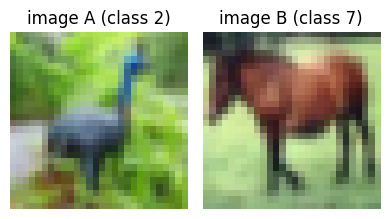

In [6]:
resize28 = transforms.Resize(28)
gt_fcn3 = resize28(gt_cifar)   # same 2 CIFAR images as Architecture A, RGB kept, just resized to 28x28

fig, axes = plt.subplots(1, 2, figsize=(4, 2.4))
for b in range(2):
    axes[b].imshow(tt_cifar(gt_fcn3[b])); axes[b].set_title("image %s (class %d)" % ("AB"[b], cifar_labels[b])); axes[b].axis('off')
plt.tight_layout(); plt.show()

[R-GAP] inverse_udldu residual: -9.53e-05
FCN3 R-GAP time: 27.4s
model's own logits: [-0.001028250071850774, -0.001053394672873935]
attack labels: [1.0, 1.0] | true CIFAR labels (unused): [2, 7]


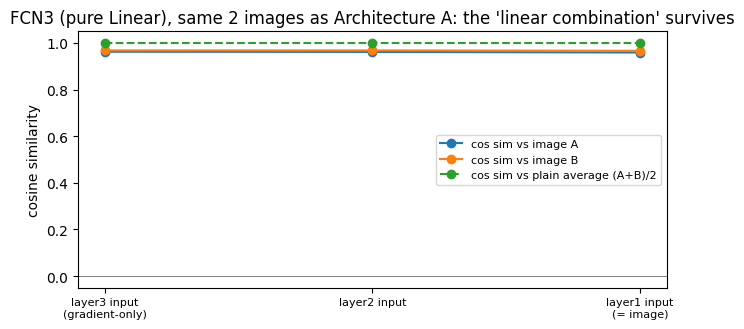

In [7]:
net_fcn3 = FCN3(input_dim=3 * 28 * 28)
t0 = time.time()
res_fcn3 = run_batch2_attack(net_fcn3, gt_fcn3, device)
print("FCN3 R-GAP time: %.1fs" % (time.time() - t0))
print("model's own logits:", res_fcn3['pred'].flatten().tolist())
print("attack labels:", res_fcn3['attack_label'].tolist(), "| true CIFAR labels (unused):", cifar_labels)

fcn3_stage_shapes = [(100,), (1000,), (3, 28, 28)]
fcn3_stage_names = ["layer3 input\n(gradient-only)", "layer2 input", "layer1 input\n(= image)"]
true_ff = res_fcn3['true_ff']
fcn3_true_A = [true_ff[1][0], true_ff[0][0], res_fcn3['gt_data64'][0]]
fcn3_true_B = [true_ff[1][1], true_ff[0][1], res_fcn3['gt_data64'][1]]

fcn3_cos_A, fcn3_cos_B, fcn3_cos_avg = plot_stage_cos_sim(
    fcn3_true_A, fcn3_true_B, res_fcn3['history'], fcn3_stage_shapes, fcn3_stage_names,
    "FCN3 (pure Linear), same 2 images as Architecture A: the 'linear combination' survives")

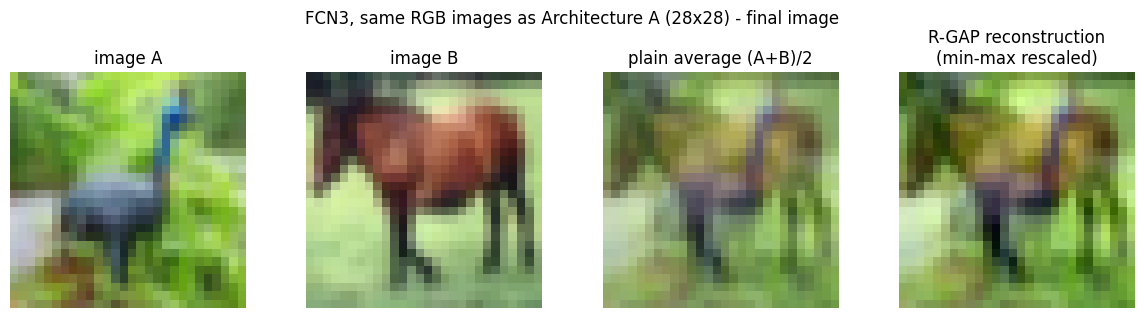

final-stage cos sim -> vs A: 0.9591 | vs B: 0.9665 | vs avg: 1.0000


In [8]:
x_rec_fcn3 = torch.tensor(res_fcn3['x_rec_flat'].reshape(3, 28, 28), dtype=torch.float32)
avg_fcn3 = gt_fcn3.mean(dim=0)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
axes[0].imshow(tt_cifar(gt_fcn3[0])); axes[0].set_title("image A"); axes[0].axis('off')
axes[1].imshow(tt_cifar(gt_fcn3[1])); axes[1].set_title("image B"); axes[1].axis('off')
axes[2].imshow(tt_cifar(avg_fcn3.clamp(0, 1))); axes[2].set_title("plain average (A+B)/2"); axes[2].axis('off')
axes[3].imshow(tt_cifar(rescale_for_display(x_rec_fcn3))); axes[3].axis('off'); axes[3].set_title("R-GAP reconstruction\n(min-max rescaled)")
plt.suptitle("FCN3, same RGB images as Architecture A (28x28) - final image")
plt.tight_layout(); plt.show()

print("final-stage cos sim -> vs A: %.4f | vs B: %.4f | vs avg: %.4f" % (fcn3_cos_A[-1], fcn3_cos_B[-1], fcn3_cos_avg[-1]))

## 3. So sánh trực tiếp hai kiến trúc

Trục hoành chuẩn hoá về "tỉ lệ độ sâu đã đi qua" (0 = layer chỉ có ràng buộc gradient, gần
output nhất; 1 = ảnh input) để so sánh được hai kiến trúc có số layer khác nhau (LeNet: 5 stage,
FCN3: 3 stage) trên cùng một trục. Dùng **trị tuyệt đối** của cosine similarity: dấu không mang
thông tin về độ khớp (xem lưu ý dấu/scale ở mục 2) — $|\cos| \approx 1$ nghĩa là khớp gần như
hoàn hảo (cùng dấu hoặc ngược dấu), $|\cos| \approx 0$ nghĩa là không còn liên hệ gì với ảnh
gốc.

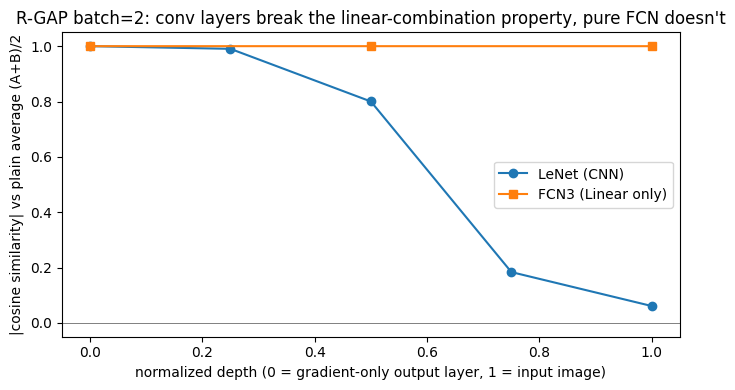

                                  LeNet/CNN  FCN3/Linear
|cos sim| @ first stage              1.0000       1.0000
|cos sim| @ final image              0.0608       1.0000


In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
cnn_x = np.linspace(0, 1, len(cnn_stage_shapes))
fcn3_x = np.linspace(0, 1, len(fcn3_stage_shapes))
ax.plot(cnn_x, np.abs(cnn_cos_avg), marker='o', label='LeNet (CNN)')
ax.plot(fcn3_x, np.abs(fcn3_cos_avg), marker='s', label='FCN3 (Linear only)')
ax.axhline(0, color='gray', lw=0.7)
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel("normalized depth (0 = gradient-only output layer, 1 = input image)")
ax.set_ylabel("|cosine similarity| vs plain average (A+B)/2")
ax.set_title("R-GAP batch=2: conv layers break the linear-combination property, pure FCN doesn't")
ax.legend()
plt.tight_layout(); plt.show()

print("%-30s %12s %12s" % ("", "LeNet/CNN", "FCN3/Linear"))
print("%-30s %12.4f %12.4f" % ("|cos sim| @ first stage", abs(cnn_cos_avg[0]), abs(fcn3_cos_avg[0])))
print("%-30s %12.4f %12.4f" % ("|cos sim| @ final image", abs(cnn_cos_avg[-1]), abs(fcn3_cos_avg[-1])))

## 4. Kết luận

| | **LeNet (CNN)** | **FCN3 (thuần Linear)** |
|---|---|---|
| Layer chỉ ràng buộc gradient (gần output nhất) | $|\cos| \approx 1.0$ | $|\cos| \approx 1.0$ |
| Ảnh cuối cùng (input) | $|\cos|$ sụp xuống gần 0 — gần như nhiễu | $|\cos|$ **vẫn ở mức cao** — vẫn là một tổ hợp tuyến tính nhận ra được (có thể ngược dấu, xem lưu ý dấu/scale ở mục 2) |
| Số conv layer | 4 | 0 |
| Ảnh input | 2 ảnh CIFAR-10 RGB (`cifar_indices`) | **đúng 2 ảnh RGB đó**, chỉ resize còn 28×28 |

Vì cả hai thí nghiệm dùng **chung một cặp ảnh, cùng 3 kênh màu**, khác biệt duy nhất giữa hai kết
quả chỉ có thể đến từ kiến trúc — loại bỏ cả khả năng "FCN3 dễ hơn vì ảnh đơn giản hơn" lẫn "vì
ảnh ít kênh màu hơn" như những lời giải thích thay thế.

**Phát biểu "R-GAP trong chế độ batch trả về linear combination" của paper là chính xác — với
điều kiện kiến trúc chỉ có Linear layer**, đúng như trường hợp FCN3 mà chính repo gốc đã test ở
batch>1 (dù trên dataset MNIST — ở đây dùng CIFAR-10 RGB để giữ đúng ảnh giống Kiến trúc A, chỉ
cần đổi `input_dim` của FCN3 cho khớp số chiều). Với kiến trúc có conv layer (LeNet ở Part 3
chính, mà repo gốc **chưa
từng** test batch>1), ràng buộc forward-pass bổ sung của mỗi conv layer phá vỡ chính tính chất
"linear combination" đó qua từng layer, khiến ảnh cuối cùng suy biến mạnh hơn nhiều so với một
"ảnh mờ".

So với `part1_batch2.ipynb` (DLG/iDLG batch=2 trên LeNet): DLG/iDLG tách được **2 ảnh riêng
biệt** ở cả kiến trúc CNN lẫn FCN, vì cơ chế của nó (tối ưu 2 dummy image độc lập) không phụ
thuộc vào loại layer. R-GAP mạnh hơn hẳn DLG/iDLG ở batch=1 (closed-form, chính xác tuyệt đối),
nhưng batch=1 **và** kiến trúc thuần Linear là hai điều kiện cần để nó hoạt động đầy đủ — DLG/iDLG
không có giới hạn tương ứng nào.

In [10]:
import numpy as np, os
RAW_DIR = r"E:\Project\Trustworthy_AI_Project\final-report\raw"
os.makedirs(RAW_DIR, exist_ok=True)

def to_np(t):
    return t.clone().detach().clamp(0, 1).float().permute(1, 2, 0).cpu().numpy().astype(np.float32)

np.savez(os.path.join(RAW_DIR, "part3_batch2.npz"),
    cnn_gt=np.stack([to_np(gt_cifar[b]) for b in range(2)]),
    cnn_avg=to_np(avg_cifar.clamp(0, 1)),
    cnn_recon=to_np(x_rec_cnn.clamp(0, 1)),
    cnn_cos_A=float(cnn_cos_A[-1]), cnn_cos_B=float(cnn_cos_B[-1]), cnn_cos_avg=float(cnn_cos_avg[-1]),
    fcn3_gt=np.stack([to_np(gt_fcn3[b]) for b in range(2)]),
    fcn3_avg=to_np(avg_fcn3.clamp(0, 1)),
    fcn3_recon=rescale_for_display(x_rec_fcn3).permute(1, 2, 0).cpu().numpy().astype(np.float32),
    fcn3_cos_A=float(fcn3_cos_A[-1]), fcn3_cos_B=float(fcn3_cos_B[-1]), fcn3_cos_avg=float(fcn3_cos_avg[-1]),
)
print("saved", os.path.join(RAW_DIR, "part3_batch2.npz"))

saved E:\Project\Trustworthy_AI_Project\final-report\raw\part3_batch2.npz
